# 08 Final leaderboard

Everything here is loaded from the forecasts saved in notebooks 01 to 07. Nothing is trained, and it runs in under a minute.

Two questions:

1. **What are future drivers worth?** How much better the forecast gets as the model is allowed to know more.
2. **What is best under one information assumption?** The ranking of models and selection strategies that a business in each scenario could actually deploy.

Every forecast is labeled with the information it needs on the cutoff date:

- **Sales history and calendar only**, including fixed item attributes;
- **Historical exogenous features**: also past prices and promotions;
- **Partial future-driver visibility**: also the promotion plan for the first four weeks (optional, notebook 03);
- **Full future-driver visibility**: also planned prices and promotions for all 14 weeks. Realized values stand in for the plan, so these scores assume the plan is carried out as recorded;
- **Leakage diagnostic**: uses information that is not available on the cutoff or is derived from the target. Shown separately and never deployable.

Scores are computed once, with `utilsforecast` for WAPE, MAE, bias and RMSSE, then APC and coverage, on the rows every model forecasts. Final-window scores (cutoff 2025-04-09) come from a window that was inspected while the notebooks were built, so they are exploratory benchmarks, not untouched holdout results. A blank APC means the model has no forecasts from earlier origins.

In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from shared.prepare_data import load_panel, series_segments, DEV_CUTOFFS, TEST_CUTOFF, STABILITY_CUTOFFS
from shared.leaderboard import load_forecasts, leaderboard, breakdown, eligible, FOLDER, TIERS, INFORMATION

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]
segments = series_segments(panel)

files = ["01_baselines", "02_ml_baseline", "03_exogenous", "03_partial_plan", "03_leakage_diagnostics", "03b_promotion_spikes", "03_catboost", "03c_behavior_features",
         "04_global_vs_specialized", "04_partition_granularity", "05_horizon_strategies", "06_objectives", "06_l1_features", "07_model_selection"]
forecasts = load_forecasts(files)
forecasts = forecasts[~forecasts.model.isin(["Selected_per_SKU", "Average"])]    # preliminary versions from 01; 07 rebuilds both

board = leaderboard(forecasts, actuals, scope="test")
board["without_future_drivers"] = [eligible(t, "no_future_drivers") for t in board.information_tier]
board["with_future_drivers"] = [eligible(t, "future_drivers") for t in board.information_tier]
columns = ["model", "information", "experiment", "wape", "bias", "mean_rmsse", "median_rmsse", "apc", "coverage"]

## 1. What future drivers are worth

One setup, more information at each step. Each column keeps the model fixed: the L2 column is the 02 baseline and its notebook 03 extensions, the L1 column their refits from notebook 06. Moving down a column adds information and nothing else, so the change is the value of that information, not of a better architecture. Development origins (chosen and compared without the final window), then the final 14 weeks.

In [3]:
individual = forecasts[forecasts.cutoff.isin(DEV_CUTOFFS)]          # strategies have no development forecasts
dev = leaderboard(individual, actuals, scope="dev").set_index("model")
final = board.set_index("model")

best_future_l1 = forecasts.query("experiment == '06_l1_features' and information_tier == 'future_drivers'").model.iloc[0]
best_future = best_future_l1.replace("lgbm_l1_", "lgbm_", 1)       # the notebook 03 choice, with L2
chain = pd.DataFrame({
    "L2": ["lgbm_baseline", "lgbm_categorical", "lgbm_hist_drivers", best_future],
    "L1": ["lgbm_l1_std", "lgbm_l1_std_categorical", "lgbm_l1_hist_drivers", best_future_l1],
}, index=["sales history and calendar", "+ item attributes", "+ attributes and historical drivers", "+ attributes and the price and promotion plan"])

value = pd.concat({
    "development WAPE": chain.apply(lambda col: col.map(dev.wape)),
    "final WAPE": chain.apply(lambda col: col.map(final.wape)),
    "final bias": chain.apply(lambda col: col.map(final.bias)),
}, axis=1)
value.round(3)

development WAPE         \
                                                            L2     L1   
sales history and calendar                               0.449  0.378   
+ item attributes                                        0.423  0.358   
+ attributes and historical drivers                      0.416  0.354   
+ attributes and the price and promotion plan            0.311  0.291   

                                              final WAPE        final bias  \
                                                      L2     L1         L2   
sales history and calendar                         0.419  0.369      0.109   
+ item attributes                                  0.400  0.350      0.105   
+ attributes and historical drivers                0.396  0.349      0.107   
+ attributes and the price and promotion plan      0.278  0.268      0.055   

                                                      
                                                  L1  
sales history and calendar                    -0.003  
+ item attributes                             -0.020  
+ attributes and historical drivers           -0.028  
+ attributes and the price and promotion plan  0.023

## 2. Final Scoreboard

In [19]:
core_experiments = [
    "01_baselines",
    "02_ml_baseline",
    "03_exogenous",
    "03b_promotion_spikes",
    "04_global_vs_specialized",
    "05_horizon_strategies",
    "06_objectives",
    "06_l1_features",
]

core_strategies = [
    "Select_stats_sku",
    "Select_ml_sku",
    "Select_all_portfolio",
    "Select_all_department",
    "Select_all_sku",
    "Select_future_portfolio",
    "Select_future_department",
    "Select_future_sku",
    "Average_stats",
    "Average_all",
    "Average_top3_ml",
    "Average_top3_future",
]

core_board = board[
    (
        board.experiment.isin(core_experiments)
        | board.model.isin(core_strategies)
    )
    & (board.information_tier != "leakage_diagnostic")
]

core_board.sort_values("wape")[columns].round(3)

,model,information,experiment,wape,bias,mean_rmsse,median_rmsse,apc,coverage
102,Average_top3_future,Full future-driver visibility,07_model_selection,0.267,0.043,1.138,0.563,0.075,1.0
103,Select_future_portfolio,Full future-driver visibility,07_model_selection,0.268,0.023,1.155,0.568,0.093,1.0
105,lgbm_l1_future_price_levels,Full future-driver visibility,06_l1_features,0.268,0.023,1.155,0.568,0.093,1.0
106,lgbm_future_discount,Full future-driver visibility,03_exogenous,0.274,0.049,1.148,0.572,0.086,1.0
107,lgbm_future_price_index,Full future-driver visibility,03_exogenous,0.276,0.052,1.147,0.571,0.084,1.0
108,lgbm_future_price_levels,Full future-driver visibility,03_exogenous,0.278,0.055,1.148,0.570,0.081,1.0
110,Select_future_department,Full future-driver visibility,07_model_selection,0.289,0.048,1.164,0.578,0.123,1.0
113,Select_future_sku,Full future-driver visibility,07_model_selection,0.298,0.056,1.204,0.595,0.101,1.0
115,lgbm_future_promo_calendar,Full future-driver visibility,03_exogenous,0.314,0.052,1.180,0.601,0.082,1.0
116,lgbm_adj_future,Full future-driver visibility,03b_promotion_spikes,0.326,0.015,1.216,0.633,0.092,1.0


In [ ]:
# Save the leaderboard to a CSV file
board.rename(columns={"experiment": "lab", "series": "n_series"}).round(5).to_csv(FOLDER / "leaderboard.csv", index=False)

## 5. Day 2 handoff

Day 2 continues on the same 2,000 series and the same final window, so its scores can sit next to these, provided the information matches:

- A Day 2 model with no covariates compares with the Day 1 models **without future drivers**.
- A Day 2 model given future covariates compares with the **future-driver** models only if its covariates are plans. The Day 2 covariates `discount_depth` and `price_index` are computed from the realized selling price, which reveals zero-sales weeks (notebook 03, optional section 12). The matching Day 1 model is `lgbm_day2_covariates_leaky`, which uses exactly those covariates and is a leakage diagnostic.
- A model or ensemble chosen with final-window scores is a leakage diagnostic.

`day2_handoff.parquet` holds the Day 1 models Day 2 compares against, at the final cutoff and the two earlier cutoffs that APC needs, in the shared format. `results/day1/README.md` has the loading example.

In [8]:
handoff_models = {
    "Naive": "last observed week",
    "SeasonalNaive": "same week last year",
    "HistoricAverage": "mean of the history",
    "lgbm_baseline": "basic global LightGBM: L2, standardized target (02)",
    "lgbm_raw": "L2, raw target (02)",
    "lgbm_l1_raw": "L1, raw target (06)",
    "lgbm_tweedie_raw": "Tweedie 1.3, raw target (06)",
    "lgbm_l1_std": "L1, standardized target (06)",
    "lgbm_categorical": "02 baseline plus department, class and subclass (03)",
    "lgbm_hist_drivers": "plus historical price and promotion drivers (03)",
    "lgbm_l1_std_categorical": "L1 version of lgbm_categorical (06)",
    "lgbm_l1_hist_drivers": "L1 version of lgbm_hist_drivers (06)",
    "Average_top3_ml": "top-three average, no future drivers (07)",
    "Average_top3_ml_behavior": "top-three average of the largest pool without future drivers (07)",
    "lgbm_future_promo_calendar": "promotion plan and calendar features (03)",
    best_future: "the price and promotion plan, the feature set notebook 03 chose (03)",
    best_future_l1: "L1 version of the same (06)",
    "Average_top3_future": "top-three average with future drivers (07)",
    "lgbm_realized_price_leaky": "leakage diagnostic: realized selling price (03)",
    "lgbm_day2_covariates_leaky": "leakage diagnostic: the Day 2 covariates promo, discount_depth, price_index (03)",
}
handoff = forecasts[forecasts.model.isin(handoff_models) & forecasts.cutoff.isin([TEST_CUTOFF] + list(STABILITY_CUTOFFS))]
handoff[["unique_id", "cutoff", "ds", "model", "yhat", "experiment", "information_tier"]].to_parquet(FOLDER / "day2_handoff.parquet", index=False)

pd.DataFrame({"description": handoff_models}).join(final[["information", "wape", "bias", "mean_rmsse", "median_rmsse", "apc"]]).round(3)

,description,information,wape,bias,mean_rmsse,median_rmsse,apc
Naive,last observed week,Sales history and calendar only,0.470,0.066,1.332,0.771,0.325
SeasonalNaive,same week last year,Sales history and calendar only,0.438,-0.037,1.525,0.929,0.000
HistoricAverage,mean of the history,Sales history and calendar only,0.426,-0.011,1.367,0.739,0.010
lgbm_baseline,"basic global LightGBM: L2, standardized target...",Sales history and calendar only,0.419,0.109,1.302,0.733,0.091
lgbm_raw,"L2, raw target (02)",Sales history and calendar only,0.505,0.215,12.000,1.065,0.164
lgbm_l1_raw,"L1, raw target (06)",Sales history and calendar only,0.375,-0.073,1.229,0.685,0.166
lgbm_tweedie_raw,"Tweedie 1.3, raw target (06)",Sales history and calendar only,0.455,0.147,1.346,0.785,0.165
lgbm_l1_std,"L1, standardized target (06)",Sales history and calendar only,0.369,-0.003,1.265,0.671,0.118
lgbm_categorical,"02 baseline plus department, class and subclas...",Sales history and calendar only,0.400,0.105,1.270,0.703,0.107
lgbm_hist_drivers,plus historical price and promotion drivers (03),Historical exogenous features,0.396,0.107,1.266,0.711,0.102


### Compact benchmark file

`day2_benchmarks.parquet` is the short version, in two groups. Without future drivers: naive, seasonal naive, the 02 baseline and the historical-driver model with L2 and L1, to compare with Day 2 models that get no covariates. With future drivers: the planned-driver model with L2 and L1, and the Day 2-covariate diagnostic, which is the Day 1 model with the same information as the Day 2 covariate models.

In [9]:
benchmarks = {
    "Naive": "without future drivers", "SeasonalNaive": "without future drivers", "lgbm_baseline": "without future drivers",
    "lgbm_hist_drivers": "without future drivers", "lgbm_l1_hist_drivers": "without future drivers",
    best_future: "with future drivers (planned)", best_future_l1: "with future drivers (planned)",
    "lgbm_day2_covariates_leaky": "with Day 2 covariates (leakage diagnostic)",
}
compact = handoff[handoff.model.isin(benchmarks)].sort_values(["model", "cutoff", "unique_id", "ds"])
compact[["unique_id", "cutoff", "ds", "model", "yhat", "experiment", "information_tier"]].to_parquet(FOLDER / "day2_benchmarks.parquet", index=False)
summary = pd.DataFrame({"group": benchmarks}).join(final[["information", "wape", "mean_rmsse", "median_rmsse"]])
summary["rows"] = compact.groupby("model").size()
summary.round(3)

,group,information,wape,mean_rmsse,median_rmsse,rows
Naive,without future drivers,Sales history and calendar only,0.470,1.332,0.771,84000
SeasonalNaive,without future drivers,Sales history and calendar only,0.438,1.525,0.929,84000
lgbm_baseline,without future drivers,Sales history and calendar only,0.419,1.302,0.733,84000
lgbm_hist_drivers,without future drivers,Historical exogenous features,0.396,1.266,0.711,84000
lgbm_l1_hist_drivers,without future drivers,Historical exogenous features,0.349,1.255,0.671,84000
lgbm_future_price_levels,with future drivers (planned),Full future-driver visibility,0.278,1.148,0.570,84000
lgbm_l1_future_price_levels,with future drivers (planned),Full future-driver visibility,0.268,1.155,0.568,84000
lgbm_day2_covariates_leaky,with Day 2 covariates (leakage diagnostic),Leakage diagnostic,0.254,1.116,0.540,84000


## 6. Accuracy against stability

Left is more stable (smaller revisions between runs four weeks apart), up is more accurate. Every deployable model and strategy with APC, marked by whether it needs future drivers.

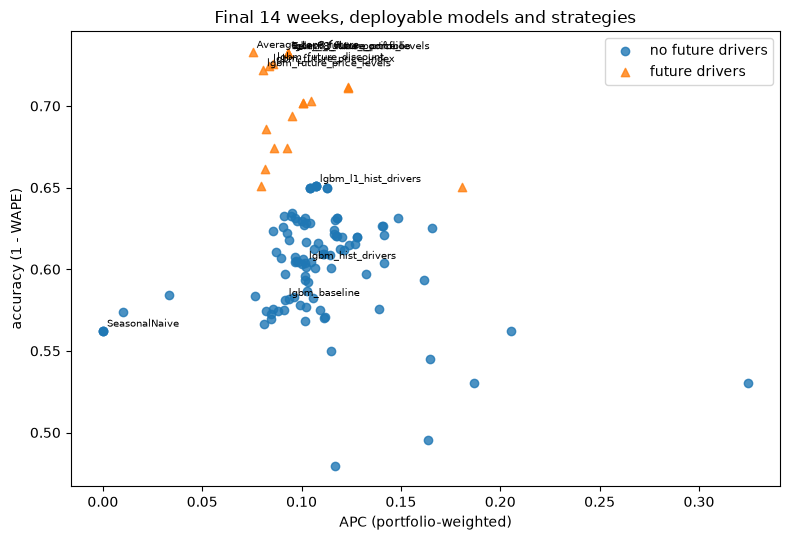

In [10]:
points = board[board.with_future_drivers & board.apc.notna()]
fig, ax = plt.subplots(figsize=(8, 5.5))
for needs, marker, label in [(False, "o", "no future drivers"), (True, "^", "future drivers")]:
    rows = points[points.without_future_drivers != needs]
    ax.scatter(rows.apc, rows.accuracy, marker=marker, label=label, alpha=0.8)
for row in pd.concat([points.nsmallest(6, "wape"), points[points.model.isin(["SeasonalNaive", "lgbm_baseline", "lgbm_hist_drivers", "lgbm_l1_hist_drivers", best_future, best_future_l1])]]).drop_duplicates("model").itertuples():
    ax.annotate(row.model, (row.apc, row.accuracy), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="APC (portfolio-weighted)", ylabel="accuracy (1 - WAPE)", title="Final 14 weeks, deployable models and strategies")
ax.legend()
plt.tight_layout()

## 7. By horizon, volume and intermittency

A few models and strategies from both scenarios, on the same pipeline. Segments are fixed from each product's history up to the final cutoff.

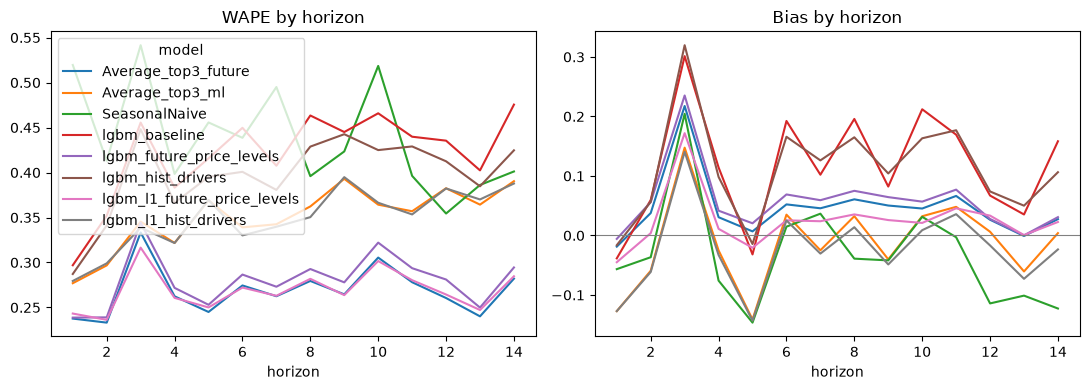

In [11]:
focus = ["SeasonalNaive", "lgbm_baseline", "lgbm_hist_drivers", "lgbm_l1_hist_drivers", best_future, best_future_l1, "Average_top3_ml", "Average_top3_future"]
pool = forecasts[forecasts.model.isin(focus)]
by_horizon = breakdown(pool, actuals, "horizon")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_horizon.pivot(index="horizon", columns="model", values="wape").plot(ax=axes[0], title="WAPE by horizon")
by_horizon.pivot(index="horizon", columns="model", values="bias").plot(ax=axes[1], title="Bias by horizon", legend=False)
axes[1].axhline(0, color="grey", lw=0.8)
plt.tight_layout()

In [12]:
volume = breakdown(pool, actuals, "volume", segments=segments)
zeros = breakdown(pool, actuals, "intermittency", segments=segments)
pd.concat({
    "wape by volume": volume.pivot(index="model", columns="volume", values="wape")[["low", "mid", "high"]],
    "bias by volume": volume.pivot(index="model", columns="volume", values="bias")[["low", "mid", "high"]],
    "wape by intermittency": zeros.pivot(index="model", columns="intermittency", values="wape")[["regular", "some_zeros", "zero_heavy"]],
    "bias by intermittency": zeros.pivot(index="model", columns="intermittency", values="bias")[["regular", "some_zeros", "zero_heavy"]],
}, axis=1).round(3)

wape by volume               bias by volume  \
                                       low    mid   high            low   
model                                                                     
Average_top3_future                  0.733  0.347  0.250         -0.555   
Average_top3_ml                      0.751  0.394  0.338         -0.597   
SeasonalNaive                        0.918  0.558  0.416         -0.698   
lgbm_baseline                        0.781  0.446  0.409         -0.544   
lgbm_future_price_levels             0.735  0.354  0.262         -0.535   
lgbm_hist_drivers                    0.746  0.426  0.386         -0.505   
lgbm_l1_future_price_levels          0.746  0.356  0.249         -0.594   
lgbm_l1_hist_drivers                 0.748  0.401  0.336         -0.590   

                                          wape by intermittency             \
                               mid   high               regular some_zeros   
model                                                                        
Average_top3_future         -0.042  0.064                 0.241      0.248   
Average_top3_ml             -0.103  0.003                 0.322      0.344   
SeasonalNaive               -0.162 -0.011                 0.371      0.503   
lgbm_baseline               -0.008  0.134                 0.388      0.405   
lgbm_future_price_levels    -0.027  0.075                 0.249      0.261   
lgbm_hist_drivers            0.028  0.127                 0.373      0.381   
lgbm_l1_future_price_levels -0.068  0.044                 0.239      0.258   
lgbm_l1_hist_drivers        -0.102 -0.010                 0.318      0.343   

                                       bias by intermittency             \
                            zero_heavy               regular some_zeros   
model                                                                     
Average_top3_future              0.888                 0.086      0.001   
Average_top3_ml                  0.901                 0.024     -0.050   
SeasonalNaive                    0.988                 0.055     -0.110   
lgbm_baseline                    1.081                 0.154      0.063   
lgbm_future_price_levels         0.948                 0.098      0.003   
lgbm_hist_drivers                0.943                 0.148      0.064   
lgbm_l1_future_price_levels      0.855                 0.061     -0.004   
lgbm_l1_hist_drivers             0.940                 0.007     -0.056   

                                        
                            zero_heavy  
model                                   
Average_top3_future             -0.297  
Average_top3_ml                 -0.428  
SeasonalNaive                   -0.962  
lgbm_baseline                   -0.229  
lgbm_future_price_levels        -0.219  
lgbm_hist_drivers               -0.214  
lgbm_l1_future_price_levels     -0.395  
lgbm_l1_hist_drivers            -0.382